In [ ]:
import numpy as np

class LogisticRegressionSR1:
    def __init__(self, learning_rate=0.3, num_iterations=100, initial_params=None):
        self.learning_rate = learning_rate
        self.num_iterations = num_iterations
        self.params = initial_params  # params = [w1, w2, ..., wn, bias]
        self.losses = []

    #sigmoid with clipping to avoid overflow
    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))


    def compute_loss(self, y_true, y_pred):
        # Cross-entropy loss with clipping to avoid log(0)
        epsilon = 1e-15
        y_pred_clipped = np.clip(y_pred, epsilon, 1 - epsilon)
        return -np.mean(y_true * np.log(y_pred_clipped) + (1 - y_true) * np.log(1 - y_pred_clipped))

    def fit(self, X, y):
        n_samples, n_features = X.shape

        # Add bias column
        X_ext = np.hstack([X, np.ones((n_samples, 1))])
        n_params = n_features + 1

        if self.params is None:
            self.params = np.zeros(n_params)

        H = np.eye(n_params)
        self.losses = []

        for i in range(self.num_iterations):
            linear_model = np.dot(X_ext, self.params)
            y_predicted = self._sigmoid(linear_model)

            loss = self.compute_loss(y, y_predicted)
            self.losses.append(loss)

            gradient = (1 / n_samples) * np.dot(X_ext.T, (y_predicted - y))

            delta_params = -np.dot(H, gradient)
            new_params = self.params + self.learning_rate * delta_params

            linear_model_new = np.dot(X_ext, new_params)
            y_predicted_new = self._sigmoid(linear_model_new)
            new_gradient = (1 / n_samples) * np.dot(X_ext.T, (y_predicted_new - y))

            s = new_params - self.params
            y_diff = new_gradient - gradient
            v = s - np.dot(H, y_diff)
            denom = np.dot(v, y_diff)

            if abs(denom) > 1e-8:
                H += np.outer(v, v) / denom

            self.params = new_params

    def predict_prob(self, X):
        n_samples = X.shape[0]
        X_ext = np.hstack([X, np.ones((n_samples, 1))])
        linear_model = np.dot(X_ext, self.params)
        return self._sigmoid(linear_model)

    def predict(self, X):
        y_predicted_probs = self.predict_prob(X)
        return (y_predicted_probs >= 0.5).astype(int)

    def get_weights_and_bias(self):
        return self.params[:-1], self.params[-1]


class LogisticRegressionSR1NonConvexReg:
    def __init__(self, learning_rate=0.3, num_iterations=100, alpha=1.0, lam=0.1, initial_params=None):
        """
        learning_rate: step size multiplier for SR1 parameter update
        num_iterations: number of training epochs
        alpha, lam: regularizer hyperparameters
        initial_params: numpy array of shape (d+1,) for weights + bias
        """
        self.learning_rate = learning_rate
        self.num_iterations = num_iterations
        self.alpha = alpha
        self.lam = lam
        self.params = initial_params
        self.losses = []

    # Sigmoid with clipping to avoid overflow
    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def normalize_features(self, X):
        # Normalize each sample vector to unit norm
        norms = np.linalg.norm(X, axis=1, keepdims=True)
        norms[norms == 0] = 1  # avoid division by zero
        return X / norms

    def compute_loss(self, X, y):
        n_samples = X.shape[0]
        weights = self.params[:-1]  # exclude bias
        bias = self.params[-1]

        linear_term = np.dot(X, weights) + bias  # includes bias

        # Numerically stable logistic loss for labels y in {0,1}
        p = self._sigmoid(linear_term)
        # Adjusting the loss function in "Fast Incremental Method for Nonconvex Optimization" to fit [0,1] classes
        logistic_losses = - (y * np.log(np.clip(p, 1e-15, 1)) + (1 - y) * np.log(np.clip(1 - p, 1e-15, 1)))
        logistic_loss = np.mean(logistic_losses)

        # Regularizer on weights AND bias
        reg_terms = self.alpha * self.params**2 / (1 + self.alpha * self.params**2)
        reg = self.lam * np.sum(reg_terms)

        return logistic_loss + reg

    def compute_gradient(self, X, y):
        n_samples = X.shape[0]
        weights = self.params[:-1]
        bias = self.params[-1]

        linear_term = np.dot(X, weights) + bias
        preds = self._sigmoid(linear_term)

        error = preds - y  # (n_samples,)

        # Gradient wrt weights
        grad_weights = (1 / n_samples) * np.dot(X.T, error)

        # Gradient wrt bias (scalar)
        grad_bias = (1 / n_samples) * np.sum(error)

        # Regularizer gradient wrt all params (weights + bias)
        reg_grad = self.lam * (2 * self.alpha * self.params) / (1 + self.alpha * self.params**2)**2

        # Add regularization gradient
        grad_weights += reg_grad[:-1]
        grad_bias += reg_grad[-1]

        # Combine into full gradient vector (weights + bias)
        gradient = np.append(grad_weights, grad_bias)
        return gradient

    def fit(self, X, y):
        X_norm = self.normalize_features(X)
        n_samples, n_features = X_norm.shape

        if self.params is None:
            self.params = np.zeros(n_features + 1)  # weights + bias

        H = np.eye(n_features + 1)
        self.losses = []

        for i in range(self.num_iterations):
            loss = self.compute_loss(X_norm, y)
            self.losses.append(loss)

            gradient = self.compute_gradient(X_norm, y)

            delta_params = -np.dot(H, gradient)
            new_params = self.params + self.learning_rate * delta_params

            new_gradient = self.compute_gradient(X_norm, y)

            s = new_params - self.params
            y_diff = new_gradient - gradient
            v = s - np.dot(H, y_diff)
            denom = np.dot(v, y_diff)

            if abs(denom) > 1e-8:  # keep abs as you requested
                H += np.outer(v, v) / denom

            self.params = new_params

    def predict_prob(self, X):
        X_norm = self.normalize_features(X)
        weights = self.params[:-1]
        bias = self.params[-1]
        linear_model = np.dot(X_norm, weights) + bias
        return self._sigmoid(linear_model)

    def predict(self, X):
        probs = self.predict_prob(X)
        return (probs >= 0.5).astype(int)

    def get_weights_and_bias(self):
        return self.params[:-1], self.params[-1]



class LogisticRegressionGD:
    def __init__(self, learning_rate=0.3, num_iterations=100, initial_params=None):
        self.learning_rate = learning_rate
        self.num_iterations = num_iterations
        self.params = initial_params  # [w1, ..., wn, bias]
        self.losses = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def compute_loss(self, y_true, y_pred):
        epsilon = 1e-15
        y_pred_clipped = np.clip(y_pred, epsilon, 1 - epsilon)
        return -np.mean(y_true * np.log(y_pred_clipped) + (1 - y_true) * np.log(1 - y_pred_clipped))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        X_ext = np.hstack([X, np.ones((n_samples, 1))])  # add bias column
        n_params = n_features + 1

        if self.params is None:
            self.params = np.zeros(n_params)

        self.losses = []

        for _ in range(self.num_iterations):
            linear_model = np.dot(X_ext, self.params)
            y_predicted = self._sigmoid(linear_model)

            loss = self.compute_loss(y, y_predicted)
            self.losses.append(loss)

            gradient = (1 / n_samples) * np.dot(X_ext.T, (y_predicted - y))
            self.params -= self.learning_rate * gradient

    def predict_prob(self, X):
        n_samples = X.shape[0]
        X_ext = np.hstack([X, np.ones((n_samples, 1))])
        linear_model = np.dot(X_ext, self.params)
        return self._sigmoid(linear_model)

    def predict(self, X):
        return (self.predict_prob(X) >= 0.5).astype(int)

    def get_weights_and_bias(self):
        return self.params[:-1], self.params[-1]

class LogisticRegressionGDNonConvexReg:
    def __init__(self, learning_rate=0.3, num_iterations=100, alpha=1.0, lam=0.1, initial_params=None):
        self.learning_rate = learning_rate
        self.num_iterations = num_iterations
        self.alpha = alpha
        self.lam = lam
        self.params = initial_params
        self.losses = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def normalize_features(self, X):
        norms = np.linalg.norm(X, axis=1, keepdims=True)
        norms[norms == 0] = 1  # avoid division by zero
        return X / norms

    def compute_loss(self, X, y):
        n_samples = X.shape[0]
        weights = self.params[:-1]
        bias = self.params[-1]

        linear_term = np.dot(X, weights) + bias
        p = self._sigmoid(linear_term)

        # Binary cross-entropy loss
        logistic_losses = - (y * np.log(np.clip(p, 1e-15, 1)) + (1 - y) * np.log(np.clip(1 - p, 1e-15, 1)))
        logistic_loss = np.mean(logistic_losses)

        # Nonconvex regularizer: alpha * x^2 / (1 + alpha * x^2)
        reg_terms = self.alpha * self.params**2 / (1 + self.alpha * self.params**2)
        reg = self.lam * np.sum(reg_terms)

        return logistic_loss + reg

    def compute_gradient(self, X, y):
        n_samples = X.shape[0]
        weights = self.params[:-1]
        bias = self.params[-1]

        linear_term = np.dot(X, weights) + bias
        preds = self._sigmoid(linear_term)
        error = preds - y

        # Gradients for weights and bias
        grad_weights = (1 / n_samples) * np.dot(X.T, error)
        grad_bias = (1 / n_samples) * np.sum(error)

        # Regularizer gradient: 2 * alpha * x / (1 + alpha * x^2)^2
        reg_grad = self.lam * (2 * self.alpha * self.params) / (1 + self.alpha * self.params**2)**2

        grad_weights += reg_grad[:-1]
        grad_bias += reg_grad[-1]

        return np.append(grad_weights, grad_bias)

    def fit(self, X, y):
        X_norm = self.normalize_features(X)
        n_samples, n_features = X_norm.shape

        if self.params is None:
            self.params = np.zeros(n_features + 1)

        self.losses = []

        for _ in range(self.num_iterations):
            loss = self.compute_loss(X_norm, y)
            self.losses.append(loss)

            gradient = self.compute_gradient(X_norm, y)
            self.params -= self.learning_rate * gradient

    def predict_prob(self, X):
        X_norm = self.normalize_features(X)
        weights = self.params[:-1]
        bias = self.params[-1]
        return self._sigmoid(np.dot(X_norm, weights) + bias)

    def predict(self, X):
        return (self.predict_prob(X) >= 0.5).astype(int)

    def get_weights_and_bias(self):
        return self.params[:-1], self.params[-1]

class LogisticRegressionSR1LineSearch:
    def __init__(self, initial_learning_rate=1.0, num_iterations=100, initial_params=None):
        self.initial_learning_rate = initial_learning_rate
        self.num_iterations = num_iterations
        self.params = initial_params
        self.losses = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def compute_loss(self, y_true, y_pred):
        epsilon = 1e-15
        y_pred_clipped = np.clip(y_pred, epsilon, 1 - epsilon)
        return -np.mean(y_true * np.log(y_pred_clipped) + (1 - y_true) * np.log(1 - y_pred_clipped))

    def _compute_gradient(self, X_ext, y, params):
        n_samples = X_ext.shape[0]
        linear_model = np.dot(X_ext, params)
        y_predicted = self._sigmoid(linear_model)
        gradient = (1 / n_samples) * np.dot(X_ext.T, (y_predicted - y))
        return gradient, y_predicted

    def _line_search(self, X_ext, y, params, direction, gradient, initial_loss, alpha=0.4, beta=0.8):
        step_size = self.initial_learning_rate
        while True:
            new_params = params + step_size * direction
            _, y_pred_new = self._compute_gradient(X_ext, y, new_params)
            new_loss = self.compute_loss(y, y_pred_new)
            if new_loss <= initial_loss + alpha * step_size * np.dot(gradient, direction):
                break
            step_size *= beta
            if step_size < 1e-8:
                break
        return step_size

    def fit(self, X, y):
        n_samples, n_features = X.shape
        X_ext = np.hstack([X, np.ones((n_samples, 1))])  # Add bias column
        n_params = X_ext.shape[1]

        if self.params is None:
            self.params = np.zeros(n_params)

        H = np.eye(n_params)
        self.losses = []

        for _ in range(self.num_iterations):
            gradient, y_pred = self._compute_gradient(X_ext, y, self.params)
            loss = self.compute_loss(y, y_pred)
            self.losses.append(loss)

            direction = -np.dot(H, gradient)
            step_size = self._line_search(X_ext, y, self.params, direction, gradient, loss)

            new_params = self.params + step_size * direction
            new_gradient, _ = self._compute_gradient(X_ext, y, new_params)

            s = new_params - self.params
            y_diff = new_gradient - gradient
            v = s - np.dot(H, y_diff)
            denom = np.dot(v, y_diff)

            if abs(denom) > 1e-8:
                H += np.outer(v, v) / denom

            self.params = new_params

    def predict_prob(self, X):
        n_samples = X.shape[0]
        X_ext = np.hstack([X, np.ones((n_samples, 1))])
        linear_model = np.dot(X_ext, self.params)
        return self._sigmoid(linear_model)

    def predict(self, X):
        return (self.predict_prob(X) >= 0.5).astype(int)

    def get_weights_and_bias(self):
        return self.params[:-1], self.params[-1]


class LogisticRegressionSR1NonConvexRegLineSearch:
    def __init__(self, initial_learning_rate=1.0, num_iterations=100, alpha=1.0, lam=0.1, initial_params=None):
        self.initial_learning_rate = initial_learning_rate
        self.num_iterations = num_iterations
        self.alpha = alpha
        self.lam = lam
        self.params = initial_params
        self.losses = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def normalize_features(self, X):
        norms = np.linalg.norm(X, axis=1, keepdims=True)
        norms[norms == 0] = 1
        return X / norms

    def compute_loss(self, X, y, params):
        n_samples = X.shape[0]
        weights = params[:-1]
        bias = params[-1]

        linear_term = np.dot(X, weights) + bias
        p = self._sigmoid(linear_term)

        logistic_losses = - (y * np.log(np.clip(p, 1e-15, 1)) + (1 - y) * np.log(np.clip(1 - p, 1e-15, 1)))
        logistic_loss = np.mean(logistic_losses)

        reg_terms = self.alpha * params**2 / (1 + self.alpha * params**2)
        reg = self.lam * np.sum(reg_terms)

        return logistic_loss + reg

    def compute_gradient(self, X, y, params):
        n_samples = X.shape[0]
        weights = params[:-1]
        bias = params[-1]

        linear_term = np.dot(X, weights) + bias
        preds = self._sigmoid(linear_term)

        error = preds - y

        grad_weights = (1 / n_samples) * np.dot(X.T, error)
        grad_bias = (1 / n_samples) * np.sum(error)

        reg_grad = self.lam * (2 * self.alpha * params) / (1 + self.alpha * params**2)**2
        grad_weights += reg_grad[:-1]
        grad_bias += reg_grad[-1]

        return np.append(grad_weights, grad_bias)

    def _line_search(self, X, y, params, direction, gradient, initial_loss, alpha=0.4, beta=0.8):
        step_size = self.initial_learning_rate
        while True:
            new_params = params + step_size * direction
            new_loss = self.compute_loss(X, y, new_params)
            if new_loss <= initial_loss + alpha * step_size * np.dot(gradient, direction):
                break
            step_size *= beta
            if step_size < 1e-8:
                break
        return step_size

    def fit(self, X, y):
        X_norm = self.normalize_features(X)
        n_samples, n_features = X_norm.shape

        if self.params is None:
            self.params = np.zeros(n_features + 1)

        H = np.eye(n_features + 1)
        self.losses = []

        for _ in range(self.num_iterations):
            loss = self.compute_loss(X_norm, y, self.params)
            self.losses.append(loss)

            gradient = self.compute_gradient(X_norm, y, self.params)
            direction = -np.dot(H, gradient)
            step_size = self._line_search(X_norm, y, self.params, direction, gradient, loss)

            new_params = self.params + step_size * direction
            new_gradient = self.compute_gradient(X_norm, y, new_params)

            s = new_params - self.params
            y_diff = new_gradient - gradient
            v = s - np.dot(H, y_diff)
            denom = np.dot(v, y_diff)

            if abs(denom) > 1e-8:
                H += np.outer(v, v) / denom

            self.params = new_params

    def predict_prob(self, X):
        X_norm = self.normalize_features(X)
        weights = self.params[:-1]
        bias = self.params[-1]
        linear_model = np.dot(X_norm, weights) + bias
        return self._sigmoid(linear_model)

    def predict(self, X):
        return (self.predict_prob(X) >= 0.5).astype(int)

    def get_weights_and_bias(self):
        return self.params[:-1], self.params[-1]


class LogisticRegressionSR1LineSearchWithHessianReg:
    def __init__(self, initial_learning_rate=1.0, num_iterations=100, hessian_reg=1e-4, initial_params=None):
        self.initial_learning_rate = initial_learning_rate
        self.num_iterations = num_iterations
        self.hessian_reg = hessian_reg  # regularization for Hessian updates
        self.params = initial_params
        self.losses = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def compute_loss(self, y_true, y_pred):
        epsilon = 1e-15
        y_pred_clipped = np.clip(y_pred, epsilon, 1 - epsilon)
        return -np.mean(y_true * np.log(y_pred_clipped) + (1 - y_true) * np.log(1 - y_pred_clipped))

    def _compute_gradient(self, X_ext, y, params):
        n_samples = X_ext.shape[0]
        linear_model = np.dot(X_ext, params)
        y_predicted = self._sigmoid(linear_model)
        gradient = (1 / n_samples) * np.dot(X_ext.T, (y_predicted - y))
        return gradient, y_predicted

    def _line_search(self, X_ext, y, params, direction, gradient, initial_loss, alpha=0.4, beta=0.8):
        step_size = self.initial_learning_rate
        while True:
            new_params = params + step_size * direction
            _, y_pred_new = self._compute_gradient(X_ext, y, new_params)
            new_loss = self.compute_loss(y, y_pred_new)
            if new_loss <= initial_loss + alpha * step_size * np.dot(gradient, direction):
                break
            step_size *= beta
            if step_size < 1e-8:
                break
        return step_size

    def fit(self, X, y):
        n_samples, n_features = X.shape
        X_ext = np.hstack([X, np.ones((n_samples, 1))])
        n_params = X_ext.shape[1]

        if self.params is None:
            self.params = np.zeros(n_params)

        H = np.eye(n_params)
        self.losses = []

        for _ in range(self.num_iterations):
            gradient, y_pred = self._compute_gradient(X_ext, y, self.params)
            loss = self.compute_loss(y, y_pred)
            self.losses.append(loss)

            direction = -np.dot(H, gradient)
            step_size = self._line_search(X_ext, y, self.params, direction, gradient, loss)

            new_params = self.params + step_size * direction
            new_gradient, _ = self._compute_gradient(X_ext, y, new_params)

            s = new_params - self.params
            y_diff = new_gradient - gradient

            v = s - np.dot(H, y_diff)
            denom = np.dot(v, y_diff)

            # SR1 update with Hessian regularization
            if abs(denom) > 1e-8:
                H += np.outer(v, v) / (denom + self.hessian_reg)

            self.params = new_params

    def predict_prob(self, X):
        n_samples = X.shape[0]
        X_ext = np.hstack([X, np.ones((n_samples, 1))])
        linear_model = np.dot(X_ext, self.params)
        return self._sigmoid(linear_model)

    def predict(self, X):
        return (self.predict_prob(X) >= 0.5).astype(int)

    def get_weights_and_bias(self):
        return self.params[:-1], self.params[-1]



class LogisticRegressionSR1NonConvexRegLineSearchWithHessianReg:
    def __init__(self, initial_learning_rate=1.0, num_iterations=100, alpha=1.0, lam=0.1, hessian_reg=1e-4, initial_params=None):
        self.initial_learning_rate = initial_learning_rate
        self.num_iterations = num_iterations
        self.alpha = alpha
        self.lam = lam
        self.hessian_reg = hessian_reg
        self.params = initial_params
        self.losses = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def normalize_features(self, X):
        norms = np.linalg.norm(X, axis=1, keepdims=True)
        norms[norms == 0] = 1
        return X / norms

    def compute_loss(self, X, y, params):
        n_samples = X.shape[0]
        weights = params[:-1]
        bias = params[-1]

        linear_term = np.dot(X, weights) + bias
        p = self._sigmoid(linear_term)

        logistic_losses = - (y * np.log(np.clip(p, 1e-15, 1)) + (1 - y) * np.log(np.clip(1 - p, 1e-15, 1)))
        logistic_loss = np.mean(logistic_losses)

        reg_terms = self.alpha * params**2 / (1 + self.alpha * params**2)
        reg = self.lam * np.sum(reg_terms)

        return logistic_loss + reg

    def compute_gradient(self, X, y, params):
        n_samples = X.shape[0]
        weights = params[:-1]
        bias = params[-1]

        linear_term = np.dot(X, weights) + bias
        preds = self._sigmoid(linear_term)
        error = preds - y

        grad_weights = (1 / n_samples) * np.dot(X.T, error)
        grad_bias = (1 / n_samples) * np.sum(error)

        reg_grad = self.lam * (2 * self.alpha * params) / (1 + self.alpha * params**2)**2

        grad_weights += reg_grad[:-1]
        grad_bias += reg_grad[-1]

        return np.append(grad_weights, grad_bias)

    def _line_search(self, X, y, params, direction, gradient, initial_loss, alpha=0.4, beta=0.8):
        step_size = self.initial_learning_rate
        while True:
            new_params = params + step_size * direction
            new_loss = self.compute_loss(X, y, new_params)
            if new_loss <= initial_loss + alpha * step_size * np.dot(gradient, direction):
                break
            step_size *= beta
            if step_size < 1e-8:
                break
        return step_size

    def fit(self, X, y):
        X_norm = self.normalize_features(X)
        n_samples, n_features = X_norm.shape

        if self.params is None:
            self.params = np.zeros(n_features + 1)

        H = np.eye(n_features + 1)
        self.losses = []

        for _ in range(self.num_iterations):
            loss = self.compute_loss(X_norm, y, self.params)
            self.losses.append(loss)

            gradient = self.compute_gradient(X_norm, y, self.params)
            direction = -np.dot(H, gradient)

            step_size = self._line_search(X_norm, y, self.params, direction, gradient, loss)
            new_params = self.params + step_size * direction
            new_gradient = self.compute_gradient(X_norm, y, new_params)

            s = new_params - self.params
            y_diff = new_gradient - gradient
            v = s - np.dot(H, y_diff)
            denom = np.dot(v, y_diff)

            # SR1 update with Hessian regularization
            if abs(denom) > 1e-8:
                H += np.outer(v, v) / (denom + self.hessian_reg)

            self.params = new_params

    def predict_prob(self, X):
        X_norm = self.normalize_features(X)
        weights = self.params[:-1]
        bias = self.params[-1]
        linear_model = np.dot(X_norm, weights) + bias
        return self._sigmoid(linear_model)

    def predict(self, X):
        return (self.predict_prob(X) >= 0.5).astype(int)

    def get_weights_and_bias(self):
        return self.params[:-1], self.params[-1]


class LogisticRegressionBFGS:
    def __init__(self, initial_learning_rate=1.0, num_iterations=100, initial_params=None):
        self.initial_learning_rate = initial_learning_rate
        self.num_iterations = num_iterations
        self.params = initial_params
        self.losses = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def compute_loss(self, y_true, y_pred):
        epsilon = 1e-15
        y_pred_clipped = np.clip(y_pred, epsilon, 1 - epsilon)
        return -np.mean(y_true * np.log(y_pred_clipped) + (1 - y_true) * np.log(1 - y_pred_clipped))

    def _compute_gradient(self, X_ext, y, params):
        n_samples = X_ext.shape[0]
        linear_model = np.dot(X_ext, params)
        y_predicted = self._sigmoid(linear_model)
        gradient = (1 / n_samples) * np.dot(X_ext.T, (y_predicted - y))
        return gradient, y_predicted

    def _line_search(self, X_ext, y, params, direction, gradient, initial_loss, alpha=0.4, beta=0.8):
        step_size = self.initial_learning_rate
        while True:
            new_params = params + step_size * direction
            _, y_pred_new = self._compute_gradient(X_ext, y, new_params)
            new_loss = self.compute_loss(y, y_pred_new)
            if new_loss <= initial_loss + alpha * step_size * np.dot(gradient, direction):
                break
            step_size *= beta
            if step_size < 1e-8:
                break
        return step_size

    def fit(self, X, y):
        n_samples, n_features = X.shape
        X_ext = np.hstack([X, np.ones((n_samples, 1))])
        n_params = X_ext.shape[1]

        if self.params is None:
            self.params = np.zeros(n_params)

        H = np.eye(n_params)
        self.losses = []

        for _ in range(self.num_iterations):
            gradient, y_pred = self._compute_gradient(X_ext, y, self.params)
            loss = self.compute_loss(y, y_pred)
            self.losses.append(loss)

            direction = -np.dot(H, gradient)
            step_size = self._line_search(X_ext, y, self.params, direction, gradient, loss)

            new_params = self.params + step_size * direction
            new_gradient, _ = self._compute_gradient(X_ext, y, new_params)

            s = new_params - self.params
            y_diff = new_gradient - gradient

            # BFGS update
            if np.dot(s, y_diff) > 1e-8:
                rho = 1.0 / np.dot(s, y_diff)
                I = np.eye(n_params)
                H = np.dot(np.dot(I - rho * np.outer(s, y_diff), H), I - rho * np.outer(y_diff, s)) + rho * np.outer(s, s)

            self.params = new_params

    def predict_prob(self, X):
        n_samples = X.shape[0]
        X_ext = np.hstack([X, np.ones((n_samples, 1))])
        linear_model = np.dot(X_ext, self.params)
        return self._sigmoid(linear_model)

    def predict(self, X):
        return (self.predict_prob(X) >= 0.5).astype(int)

    def get_weights_and_bias(self):
        return self.params[:-1], self.params[-1]


class LogisticRegressionBFGSNonConvex:
    def __init__(self, initial_learning_rate=1.0, num_iterations=100, alpha=1.0, lam=0.1, initial_params=None):
        self.initial_learning_rate = initial_learning_rate
        self.num_iterations = num_iterations
        self.alpha = alpha
        self.lam = lam
        self.params = initial_params
        self.losses = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def normalize_features(self, X):
        norms = np.linalg.norm(X, axis=1, keepdims=True)
        norms[norms == 0] = 1
        return X / norms

    def compute_loss(self, X, y, params):
        n_samples = X.shape[0]
        weights = params[:-1]
        bias = params[-1]

        linear_term = np.dot(X, weights) + bias
        p = self._sigmoid(linear_term)

        logistic_losses = - (y * np.log(np.clip(p, 1e-15, 1)) + (1 - y) * np.log(np.clip(1 - p, 1e-15, 1)))
        logistic_loss = np.mean(logistic_losses)

        reg_terms = self.alpha * params**2 / (1 + self.alpha * params**2)
        reg = self.lam * np.sum(reg_terms)

        return logistic_loss + reg

    def compute_gradient(self, X, y, params):
        n_samples = X.shape[0]
        weights = params[:-1]
        bias = params[-1]

        linear_term = np.dot(X, weights) + bias
        preds = self._sigmoid(linear_term)
        error = preds - y

        grad_weights = (1 / n_samples) * np.dot(X.T, error)
        grad_bias = (1 / n_samples) * np.sum(error)

        reg_grad = self.lam * (2 * self.alpha * params) / (1 + self.alpha * params**2)**2

        grad_weights += reg_grad[:-1]
        grad_bias += reg_grad[-1]

        return np.append(grad_weights, grad_bias)

    def _line_search(self, X, y, params, direction, gradient, initial_loss, alpha=0.4, beta=0.8):
        step_size = self.initial_learning_rate
        while True:
            new_params = params + step_size * direction
            new_loss = self.compute_loss(X, y, new_params)
            if new_loss <= initial_loss + alpha * step_size * np.dot(gradient, direction):
                break
            step_size *= beta
            if step_size < 1e-8:
                break
        return step_size

    def fit(self, X, y):
        X_norm = self.normalize_features(X)
        n_samples, n_features = X_norm.shape

        if self.params is None:
            self.params = np.zeros(n_features + 1)

        H = np.eye(n_features + 1)
        self.losses = []

        for _ in range(self.num_iterations):
            loss = self.compute_loss(X_norm, y, self.params)
            self.losses.append(loss)

            gradient = self.compute_gradient(X_norm, y, self.params)
            direction = -np.dot(H, gradient)
            step_size = self._line_search(X_norm, y, self.params, direction, gradient, loss)

            new_params = self.params + step_size * direction
            new_gradient = self.compute_gradient(X_norm, y, new_params)

            s = new_params - self.params
            y_diff = new_gradient - gradient

            # BFGS update
            if np.dot(s, y_diff) > 1e-8:
                rho = 1.0 / np.dot(s, y_diff)
                I = np.eye(n_features + 1)
                H = np.dot(np.dot(I - rho * np.outer(s, y_diff), H), I - rho * np.outer(y_diff, s)) + rho * np.outer(s, s)

            self.params = new_params

    def predict_prob(self, X):
        X_norm = self.normalize_features(X)
        weights = self.params[:-1]
        bias = self.params[-1]
        linear_model = np.dot(X_norm, weights) + bias
        return self._sigmoid(linear_model)

    def predict(self, X):
        return (self.predict_prob(X) >= 0.5).astype(int)

    def get_weights_and_bias(self):
        return self.params[:-1], self.params[-1]


class LogisticRegressionDFP:
    def __init__(self, learning_rate=0.3, num_iterations=100, initial_params=None):
        self.learning_rate = learning_rate
        self.num_iterations = num_iterations
        self.params = initial_params
        self.losses = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def compute_loss(self, y_true, y_pred):
        epsilon = 1e-15
        y_pred_clipped = np.clip(y_pred, epsilon, 1 - epsilon)
        return -np.mean(y_true * np.log(y_pred_clipped) + (1 - y_true) * np.log(1 - y_pred_clipped))

    def fit(self, X, y):
        n_samples, n_features = X.shape

        X_ext = np.hstack([X, np.ones((n_samples, 1))])
        n_params = n_features + 1

        if self.params is None:
            self.params = np.zeros(n_params)

        H = np.eye(n_params)
        self.losses = []

        for i in range(self.num_iterations):
            linear_model = np.dot(X_ext, self.params)
            y_predicted = self._sigmoid(linear_model)

            loss = self.compute_loss(y, y_predicted)
            self.losses.append(loss)

            gradient = (1 / n_samples) * np.dot(X_ext.T, (y_predicted - y))

            delta_params = -np.dot(H, gradient)
            new_params = self.params + self.learning_rate * delta_params

            linear_model_new = np.dot(X_ext, new_params)
            y_predicted_new = self._sigmoid(linear_model_new)
            new_gradient = (1 / n_samples) * np.dot(X_ext.T, (y_predicted_new - y))

            s = new_params - self.params
            y_diff = new_gradient - gradient

            # DFP update
            if np.dot(s, y_diff) > 1e-8:
                Hy = np.dot(H, y_diff)
                H = H + np.outer(s, s) / np.dot(s, y_diff) - np.outer(Hy, Hy) / np.dot(y_diff, Hy)

            self.params = new_params

    def predict_prob(self, X):
        n_samples = X.shape[0]
        X_ext = np.hstack([X, np.ones((n_samples, 1))])
        linear_model = np.dot(X_ext, self.params)
        return self._sigmoid(linear_model)

    def predict(self, X):
        return (self.predict_prob(X) >= 0.5).astype(int)

    def get_weights_and_bias(self):
        return self.params[:-1], self.params[-1]


class LogisticRegressionNonConvexDFP:
    def __init__(self, learning_rate=0.3, num_iterations=100, alpha=1.0, lam=0.1, initial_params=None):
        self.learning_rate = learning_rate
        self.num_iterations = num_iterations
        self.alpha = alpha
        self.lam = lam
        self.params = initial_params
        self.losses = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def normalize_features(self, X):
        norms = np.linalg.norm(X, axis=1, keepdims=True)
        norms[norms == 0] = 1
        return X / norms

    def compute_loss(self, X, y):
        n_samples = X.shape[0]
        weights = self.params[:-1]
        bias = self.params[-1]

        linear_term = np.dot(X, weights) + bias
        p = self._sigmoid(linear_term)

        logistic_losses = - (y * np.log(np.clip(p, 1e-15, 1)) + (1 - y) * np.log(np.clip(1 - p, 1e-15, 1)))
        logistic_loss = np.mean(logistic_losses)

        reg_terms = self.alpha * self.params**2 / (1 + self.alpha * self.params**2)
        reg = self.lam * np.sum(reg_terms)

        return logistic_loss + reg

    def compute_gradient(self, X, y):
        n_samples = X.shape[0]
        weights = self.params[:-1]
        bias = self.params[-1]

        linear_term = np.dot(X, weights) + bias
        preds = self._sigmoid(linear_term)
        error = preds - y

        grad_weights = (1 / n_samples) * np.dot(X.T, error)
        grad_bias = (1 / n_samples) * np.sum(error)

        reg_grad = self.lam * (2 * self.alpha * self.params) / (1 + self.alpha * self.params**2)**2

        grad_weights += reg_grad[:-1]
        grad_bias += reg_grad[-1]

        return np.append(grad_weights, grad_bias)

    def fit(self, X, y):
        X_norm = self.normalize_features(X)
        n_samples, n_features = X_norm.shape

        if self.params is None:
            self.params = np.zeros(n_features + 1)

        H = np.eye(n_features + 1)
        self.losses = []

        for i in range(self.num_iterations):
            loss = self.compute_loss(X_norm, y)
            self.losses.append(loss)

            gradient = self.compute_gradient(X_norm, y)

            delta_params = -np.dot(H, gradient)
            new_params = self.params + self.learning_rate * delta_params

            new_gradient = self.compute_gradient(X_norm, y)

            s = new_params - self.params
            y_diff = new_gradient - gradient

            # DFP update
            if np.dot(s, y_diff) > 1e-8:
                Hy = np.dot(H, y_diff)
                H = H + np.outer(s, s) / np.dot(s, y_diff) - np.outer(Hy, Hy) / np.dot(y_diff, Hy)

            self.params = new_params

    def predict_prob(self, X):
        X_norm = self.normalize_features(X)
        weights = self.params[:-1]
        bias = self.params[-1]
        linear_model = np.dot(X_norm, weights) + bias
        return self._sigmoid(linear_model)

    def predict(self, X):
        return (self.predict_prob(X) >= 0.5).astype(int)

    def get_weights_and_bias(self):
        return self.params[:-1], self.params[-1]


class LogisticRegressionDFPLineSearch:
    def __init__(self, initial_learning_rate=1.0, num_iterations=100, initial_params=None):
        self.initial_learning_rate = initial_learning_rate
        self.num_iterations = num_iterations
        self.params = initial_params
        self.losses = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def compute_loss(self, y_true, y_pred):
        epsilon = 1e-15
        y_pred_clipped = np.clip(y_pred, epsilon, 1 - epsilon)
        return -np.mean(y_true * np.log(y_pred_clipped) + (1 - y_true) * np.log(1 - y_pred_clipped))

    def _compute_gradient(self, X_ext, y, params):
        n_samples = X_ext.shape[0]
        linear_model = np.dot(X_ext, params)
        y_predicted = self._sigmoid(linear_model)
        gradient = (1 / n_samples) * np.dot(X_ext.T, (y_predicted - y))
        return gradient, y_predicted

    def _line_search(self, X_ext, y, params, direction, gradient, initial_loss, alpha=0.4, beta=0.8):
        step_size = self.initial_learning_rate
        while True:
            new_params = params + step_size * direction
            _, y_pred_new = self._compute_gradient(X_ext, y, new_params)
            new_loss = self.compute_loss(y, y_pred_new)
            if new_loss <= initial_loss + alpha * step_size * np.dot(gradient, direction):
                break
            step_size *= beta
            if step_size < 1e-8:
                break
        return step_size

    def fit(self, X, y):
        n_samples, n_features = X.shape
        X_ext = np.hstack([X, np.ones((n_samples, 1))])
        n_params = X_ext.shape[1]

        if self.params is None:
            self.params = np.zeros(n_params)

        H = np.eye(n_params)
        self.losses = []

        for _ in range(self.num_iterations):
            gradient, y_pred = self._compute_gradient(X_ext, y, self.params)
            loss = self.compute_loss(y, y_pred)
            self.losses.append(loss)

            direction = -np.dot(H, gradient)
            step_size = self._line_search(X_ext, y, self.params, direction, gradient, loss)

            new_params = self.params + step_size * direction
            new_gradient, _ = self._compute_gradient(X_ext, y, new_params)

            s = new_params - self.params
            y_diff = new_gradient - gradient

            # DFP update
            if np.dot(s, y_diff) > 1e-8:
                Hy = np.dot(H, y_diff)
                H = H + np.outer(s, s) / np.dot(s, y_diff) - np.outer(Hy, Hy) / np.dot(y_diff, Hy)

            self.params = new_params

    def predict_prob(self, X):
        n_samples = X.shape[0]
        X_ext = np.hstack([X, np.ones((n_samples, 1))])
        linear_model = np.dot(X_ext, self.params)
        return self._sigmoid(linear_model)

    def predict(self, X):
        return (self.predict_prob(X) >= 0.5).astype(int)

    def get_weights_and_bias(self):
        return self.params[:-1], self.params[-1]


class LogisticRegressionDFPNonConvexLineSearch:
    def __init__(self, initial_learning_rate=1.0, num_iterations=100, alpha=1.0, lam=0.1, initial_params=None):
        self.initial_learning_rate = initial_learning_rate
        self.num_iterations = num_iterations
        self.alpha = alpha
        self.lam = lam
        self.params = initial_params
        self.losses = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def normalize_features(self, X):
        norms = np.linalg.norm(X, axis=1, keepdims=True)
        norms[norms == 0] = 1
        return X / norms

    def compute_loss(self, X, y, params):
        n_samples = X.shape[0]
        weights = params[:-1]
        bias = params[-1]

        linear_term = np.dot(X, weights) + bias
        p = self._sigmoid(linear_term)

        logistic_losses = - (y * np.log(np.clip(p, 1e-15, 1)) + (1 - y) * np.log(np.clip(1 - p, 1e-15, 1)))
        logistic_loss = np.mean(logistic_losses)

        reg_terms = self.alpha * params**2 / (1 + self.alpha * params**2)
        reg = self.lam * np.sum(reg_terms)

        return logistic_loss + reg

    def compute_gradient(self, X, y, params):
        n_samples = X.shape[0]
        weights = params[:-1]
        bias = params[-1]

        linear_term = np.dot(X, weights) + bias
        preds = self._sigmoid(linear_term)
        error = preds - y

        grad_weights = (1 / n_samples) * np.dot(X.T, error)
        grad_bias = (1 / n_samples) * np.sum(error)

        reg_grad = self.lam * (2 * self.alpha * params) / (1 + self.alpha * params**2)**2

        grad_weights += reg_grad[:-1]
        grad_bias += reg_grad[-1]

        return np.append(grad_weights, grad_bias)

    def _line_search(self, X, y, params, direction, gradient, initial_loss, alpha=0.4, beta=0.8):
        step_size = self.initial_learning_rate
        while True:
            new_params = params + step_size * direction
            new_loss = self.compute_loss(X, y, new_params)
            if new_loss <= initial_loss + alpha * step_size * np.dot(gradient, direction):
                break
            step_size *= beta
            if step_size < 1e-8:
                break
        return step_size

    def fit(self, X, y):
        X_norm = self.normalize_features(X)
        n_samples, n_features = X_norm.shape

        if self.params is None:
            self.params = np.zeros(n_features + 1)

        H = np.eye(n_features + 1)
        self.losses = []

        for _ in range(self.num_iterations):
            loss = self.compute_loss(X_norm, y, self.params)
            self.losses.append(loss)

            gradient = self.compute_gradient(X_norm, y, self.params)
            direction = -np.dot(H, gradient)
            step_size = self._line_search(X_norm, y, self.params, direction, gradient, loss)

            new_params = self.params + step_size * direction
            new_gradient = self.compute_gradient(X_norm, y, new_params)

            s = new_params - self.params
            y_diff = new_gradient - gradient

            # DFP update
            if np.dot(s, y_diff) > 1e-8:
                Hy = np.dot(H, y_diff)
                H = H + np.outer(s, s) / np.dot(s, y_diff) - np.outer(Hy, Hy) / np.dot(y_diff, Hy)

            self.params = new_params

    def predict_prob(self, X):
        X_norm = self.normalize_features(X)
        weights = self.params[:-1]
        bias = self.params[-1]
        linear_model = np.dot(X_norm, weights) + bias
        return self._sigmoid(linear_model)

    def predict(self, X):
        return (self.predict_prob(X) >= 0.5).astype(int)

    def get_weights_and_bias(self):
        return self.params[:-1], self.params[-1]



Running SR1
Running SR1_LineSearch
Running SR1_LineSearch_Hessian
Running GD
Running BFGS
Running DFP
Running DFP Line Search
Running SR1_NonConvex
Running SR1_LineSearch_NonConvex
Running SR1_LineSearch_Hessian_NonConvex
Running GD_NonConvex
Running BFGS Non Convex
Running DFP Non Convex
Running DFP_NonConvex_LineSearch


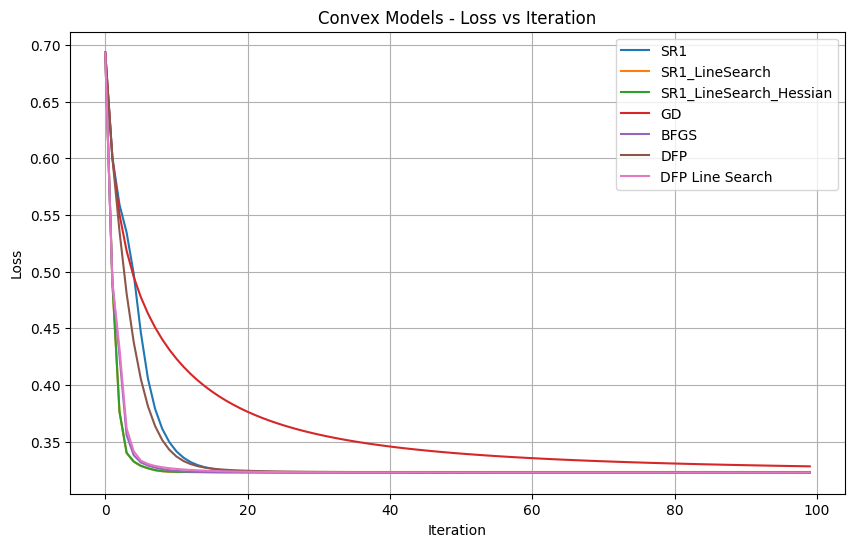

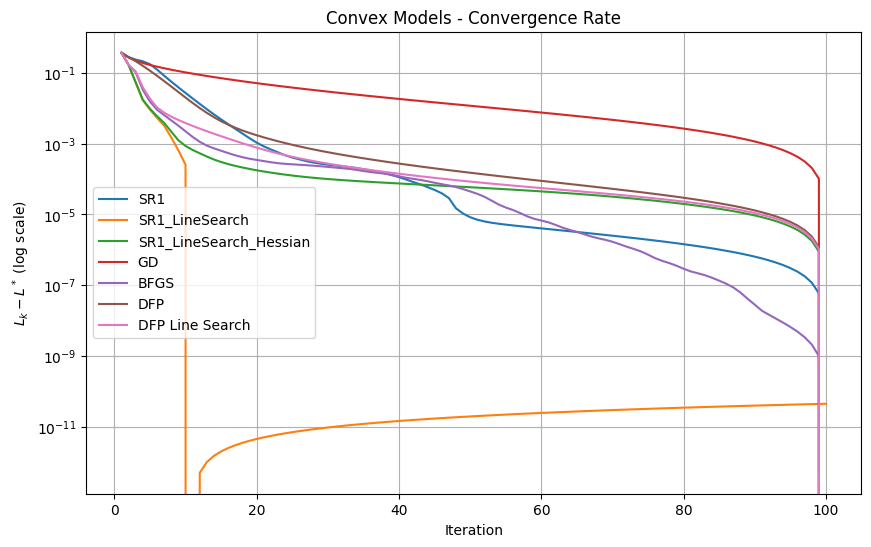

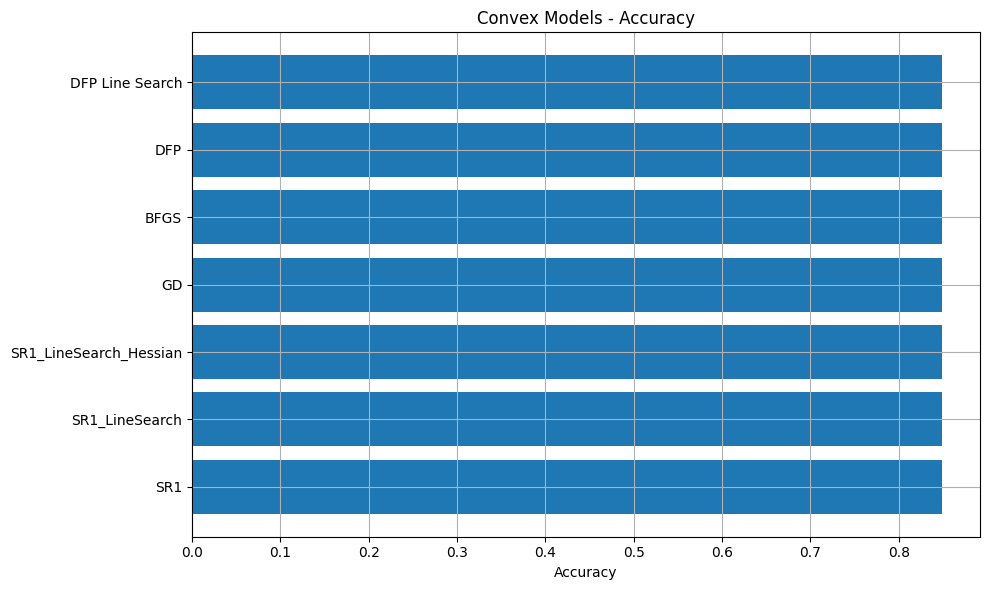

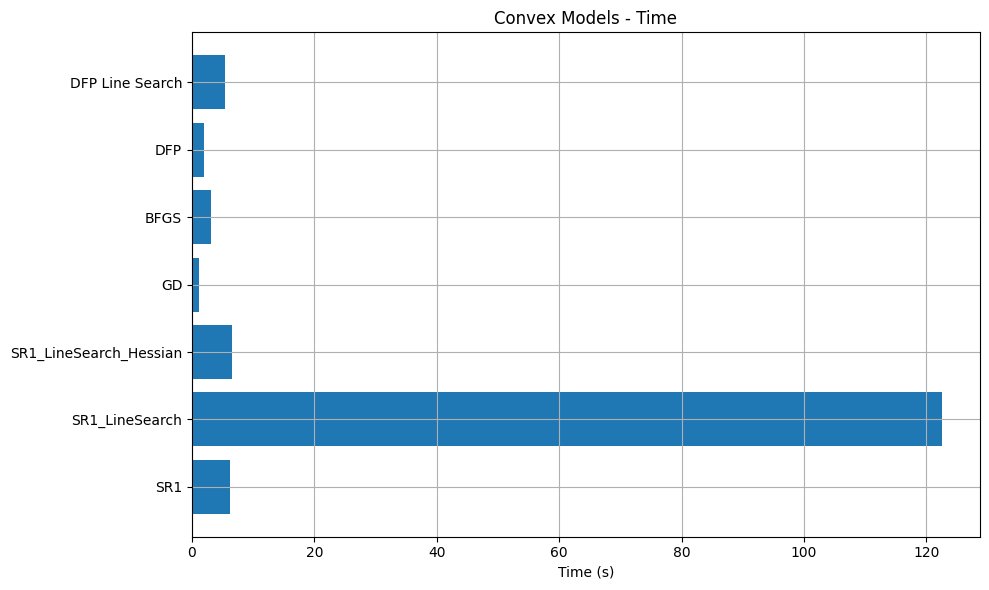

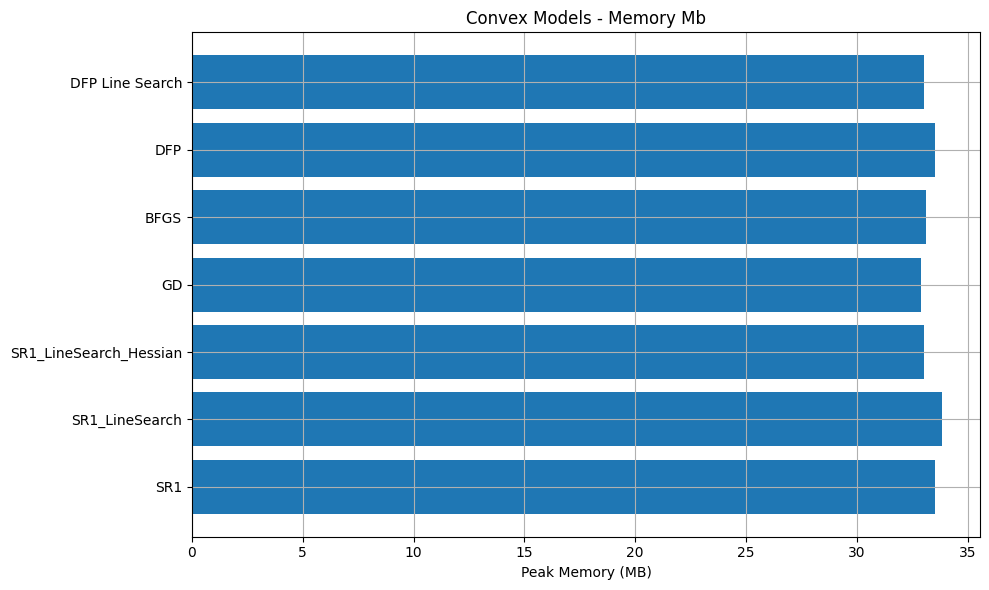

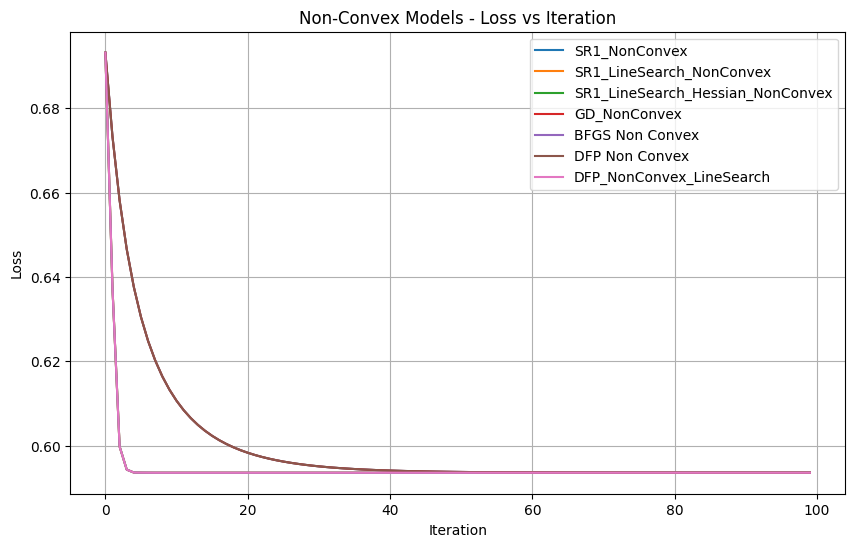

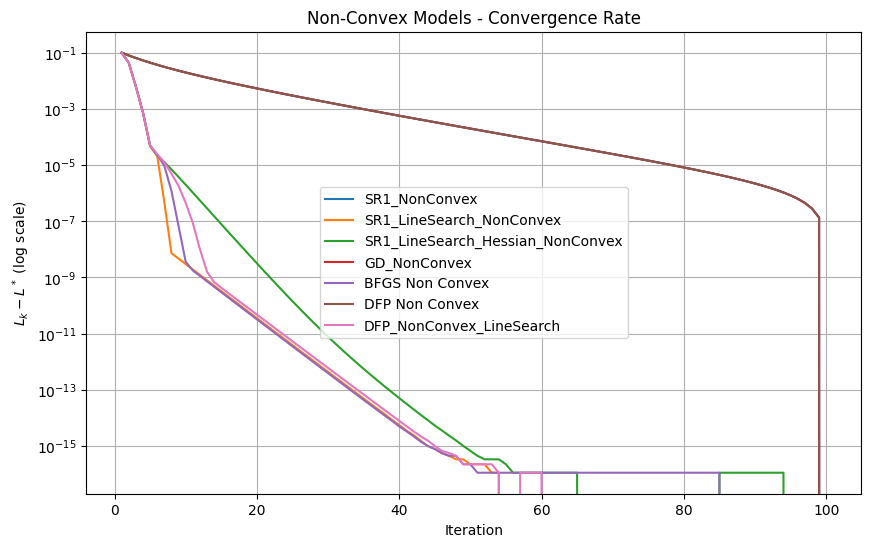

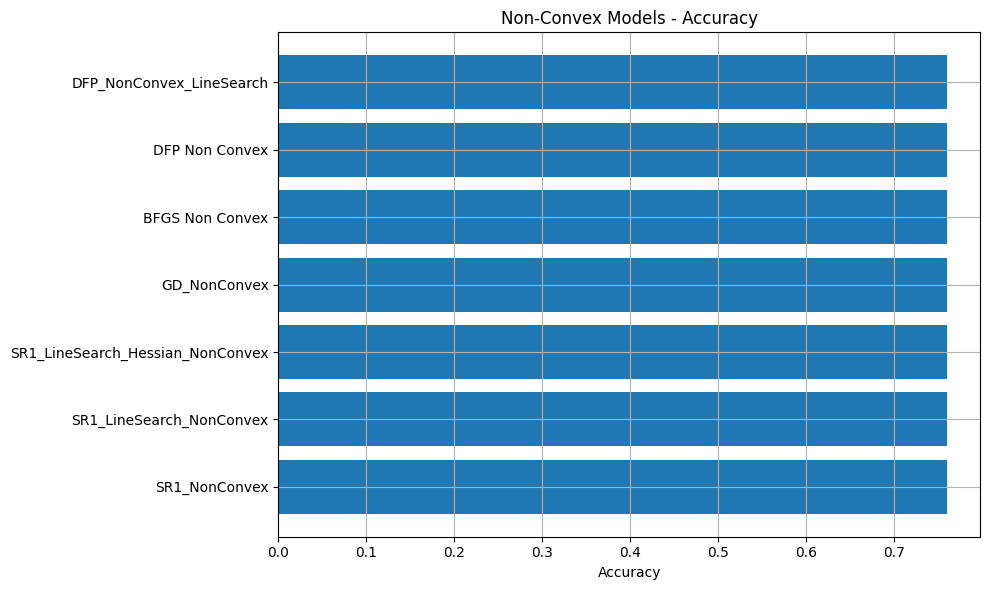

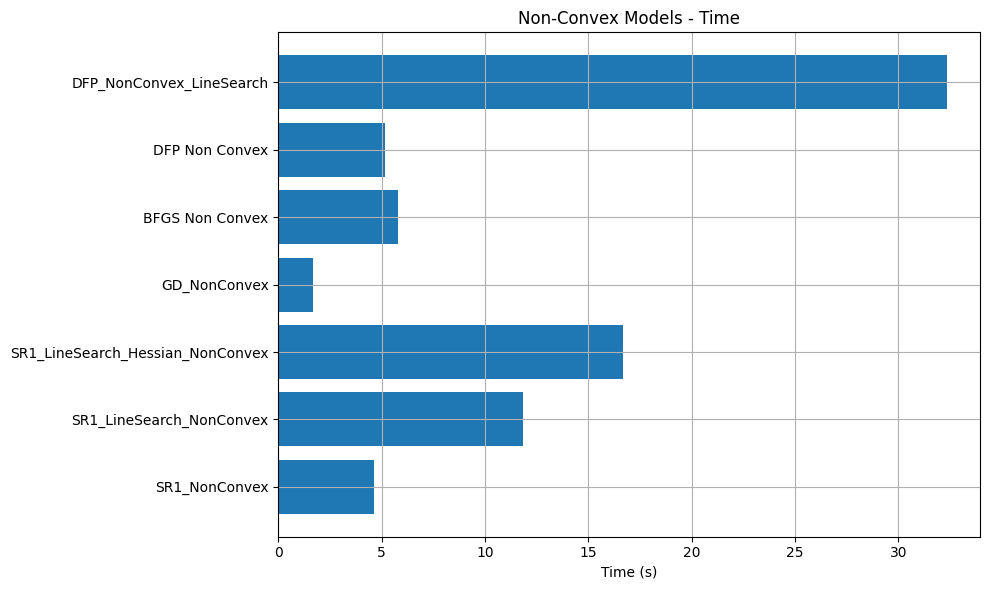

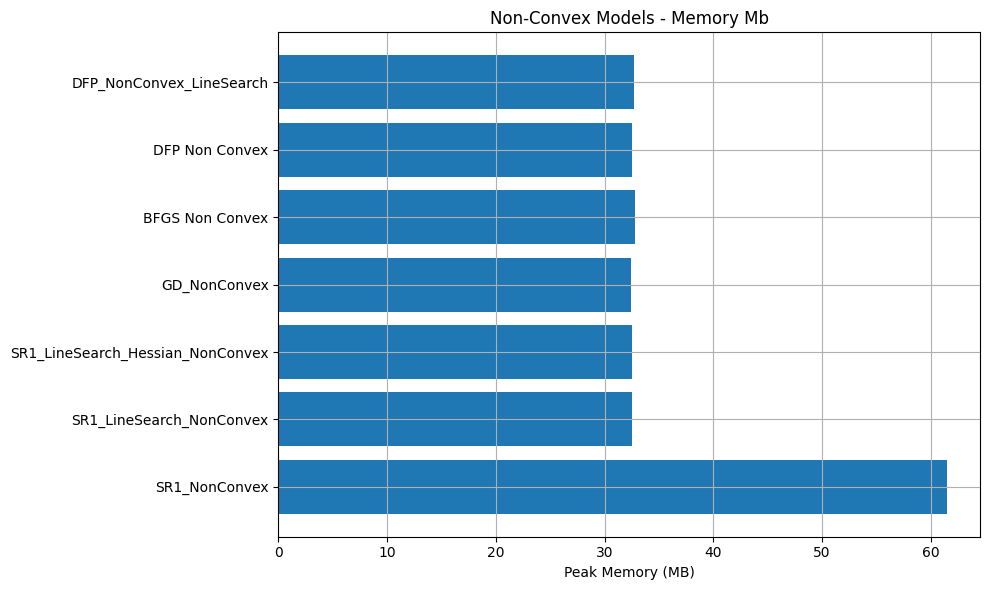


Convex Models - Convergence Summary (ε=1e-06, patience=5)
| Model                  |   Convergence Iteration |   Accuracy |
|------------------------|-------------------------|------------|
| SR1                    |                      51 |     0.8494 |
| SR1_LineSearch         |                      11 |     0.8487 |
| SR1_LineSearch_Hessian |                      88 |     0.8493 |
| GD                     |                     100 |     0.8488 |
| BFGS                   |                      59 |     0.8491 |
| DFP                    |                     100 |     0.8495 |
| DFP Line Search        |                     100 |     0.8496 |

Non-Convex Models - Convergence Summary (ε=1e-06, patience=5)
| Model                            |   Convergence Iteration |   Accuracy |
|----------------------------------|-------------------------|------------|
| SR1_NonConvex                    |                      79 |     0.7592 |
| SR1_LineSearch_NonConvex         |                    

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time
from tabulate import tabulate
import tracemalloc
from sklearn.datasets import load_svmlight_file
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Load A9a dataset
file_path = '/content/drive/MyDrive/data/a9a.txt'
X, y = load_svmlight_file(file_path)
X = X.toarray()

# Normalize features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Convert y from {-1, 1} to {0, 1}
y[y == -1] = 0

# Define your model classes
convex_model_classes = {
    "SR1": LogisticRegressionSR1,
    "SR1_LineSearch": LogisticRegressionSR1LineSearch,
    "SR1_LineSearch_Hessian": LogisticRegressionSR1LineSearchWithHessianReg,
    "GD": LogisticRegressionGD,
    "BFGS": LogisticRegressionBFGS,
    "DFP": LogisticRegressionDFP,
    "DFP Line Search": LogisticRegressionDFPLineSearch,



}

nonconvex_model_classes = {
    "SR1_NonConvex": LogisticRegressionSR1NonConvexReg,
    "SR1_LineSearch_NonConvex": LogisticRegressionSR1NonConvexRegLineSearch,
    "SR1_LineSearch_Hessian_NonConvex": LogisticRegressionSR1NonConvexRegLineSearchWithHessianReg,
    "GD_NonConvex": LogisticRegressionGDNonConvexReg,
    "BFGS Non Convex": LogisticRegressionBFGSNonConvex,
    "DFP Non Convex": LogisticRegressionNonConvexDFP,
    "DFP_NonConvex_LineSearch": LogisticRegressionDFPNonConvexLineSearch


}

# Utility to run experiment
def run_experiment(model_class, X, y, model_name):
    initial_params = np.zeros(X.shape[1] + 1)
    model = model_class(initial_params=initial_params)

    tracemalloc.start()
    start_time = time.time()
    model.fit(X, y)
    end_time = time.time()
    current, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    y_pred = model.predict(X)
    acc = accuracy_score(y, y_pred)

    return {
        "model": model_name,
        "step_size": None,
        "time": end_time - start_time,
        "memory_MB": peak / (1024 ** 2),
        "losses": model.losses,
        "accuracy": acc
    }

# Run convex experiments
convex_results = []
for name, cls in convex_model_classes.items():
    print(f"Running {name}")
    try:
        result = run_experiment(cls, X, y, model_name=name)
        convex_results.append(result)
    except Exception as e:
        print(f"Failed for {name}: {e}")

# Run non-convex experiments
nonconvex_results = []
for name, cls in nonconvex_model_classes.items():
    print(f"Running {name}")
    try:
        result = run_experiment(cls, X, y, model_name=name)
        nonconvex_results.append(result)
    except Exception as e:
        print(f"Failed for {name}: {e}")

# Plotting function (unchanged)
def plot_results(results, title_prefix):
    # Loss vs Iteration
    plt.figure(figsize=(10,6))
    for res in results:
        label = f"{res['model']}"
        plt.plot(res['losses'], label=label)
    plt.xlabel("Iteration")
    plt.ylabel("Loss")
    plt.title(f"{title_prefix} - Loss vs Iteration")
    plt.legend()
    plt.grid(True)
    plt.show()

    # Convergence plot (log scale)
    plt.figure(figsize=(10,6))
    for res in results:
        losses = np.array(res["losses"])
        L_star = np.min(losses)
        errors = losses - L_star
        label = f"{res['model']}"
        plt.plot(range(1, len(errors)+1), errors, label=label)
    plt.yscale('log')
    plt.xlabel("Iteration")
    plt.ylabel(r"$L_k - L^*$ (log scale)")
    plt.title(f"{title_prefix} - Convergence Rate")
    plt.legend()
    plt.grid(True)
    plt.show()

    # Accuracy bar plot
    plt.figure(figsize=(10,6))
    names = []
    accs = []
    for res in results:
        label = f"{res['model']}"
        names.append(label)
        accs.append(res['accuracy'])
    plt.barh(names, accs)
    plt.xlabel("Accuracy")
    plt.title(f"{title_prefix} - Accuracy")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Time and memory
    for metric in ["time", "memory_MB"]:
        plt.figure(figsize=(10,6))
        vals = [res[metric] for res in results]
        plt.barh(names, vals)
        plt.xlabel("Time (s)" if metric == "time" else "Peak Memory (MB)")
        plt.title(f"{title_prefix} - {metric.replace('_', ' ').title()}")
        plt.grid(True)
        plt.tight_layout()
        plt.show()

# Plot convex and non-convex results separately
plot_results(convex_results, "Convex Models")
plot_results(nonconvex_results, "Non-Convex Models")


def detect_convergence(losses, epsilon=1e-6, patience=5):
    """
    Returns the iteration at which convergence is detected.
    Convergence is defined as `patience` consecutive changes below `epsilon`.
    Returns len(losses) if convergence was never reached.
    """
    counter = 0
    for i in range(1, len(losses)):
        delta = abs(losses[i] - losses[i-1])
        if delta < epsilon:
            counter += 1
            if counter >= patience:
                return i - patience + 1  # point where stability started
        else:
            counter = 0
    return len(losses)

def summarize_convergence(results, title, epsilon=1e-6, patience=5):
    print(f"\n{title} - Convergence Summary (ε={epsilon}, patience={patience})")
    table = []
    for res in results:
        model_name = res["model"]
        losses = res["losses"]
        conv_iter = detect_convergence(losses, epsilon=epsilon, patience=patience)
        accuracy = res["accuracy"]
        table.append([model_name, conv_iter, f"{accuracy:.4f}"])
    print(tabulate(table, headers=["Model", "Convergence Iteration", "Accuracy"], tablefmt="github"))

summarize_convergence(convex_results, "Convex Models")
summarize_convergence(nonconvex_results, "Non-Convex Models")


<class 'numpy.ndarray'> (581012, 54)
<class 'numpy.ndarray'> (581012,)
Running SR1
Running SR1_LineSearch
Running SR1_LineSearch_Hessian
Running GD
Running BFGS
Running DFP
Running DFP Line Search
Running SR1_NonConvex
Running SR1_LineSearch_NonConvex
Running SR1_LineSearch_Hessian_NonConvex
Running GD_NonConvex
Running BFGS Non Convex
Running DFP Non Convex
Running DFP_NonConvex_LineSearch


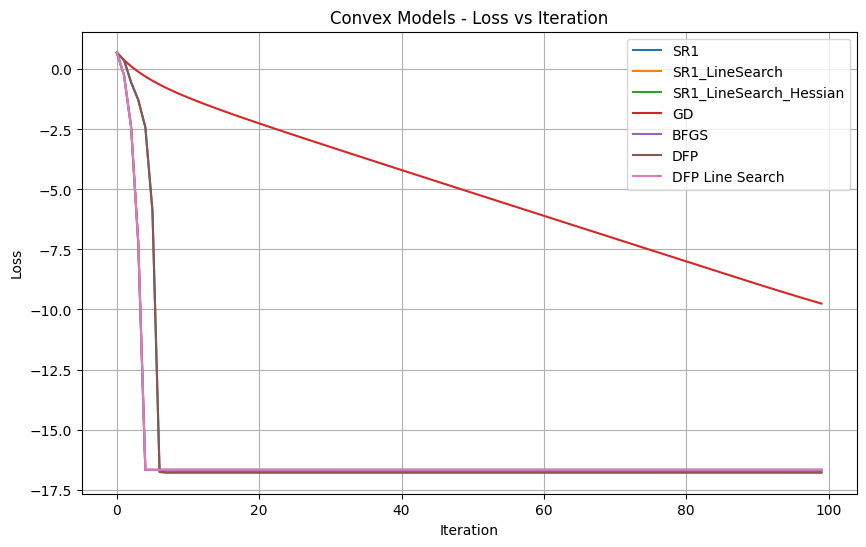

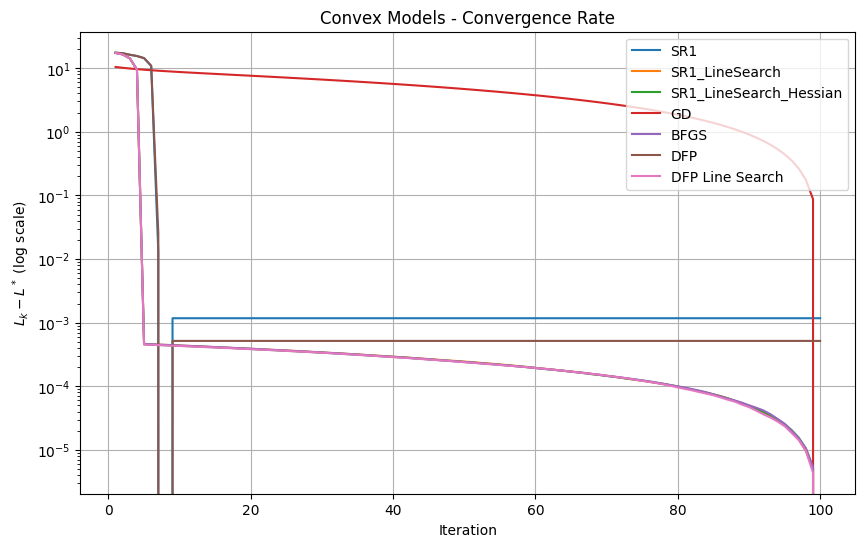

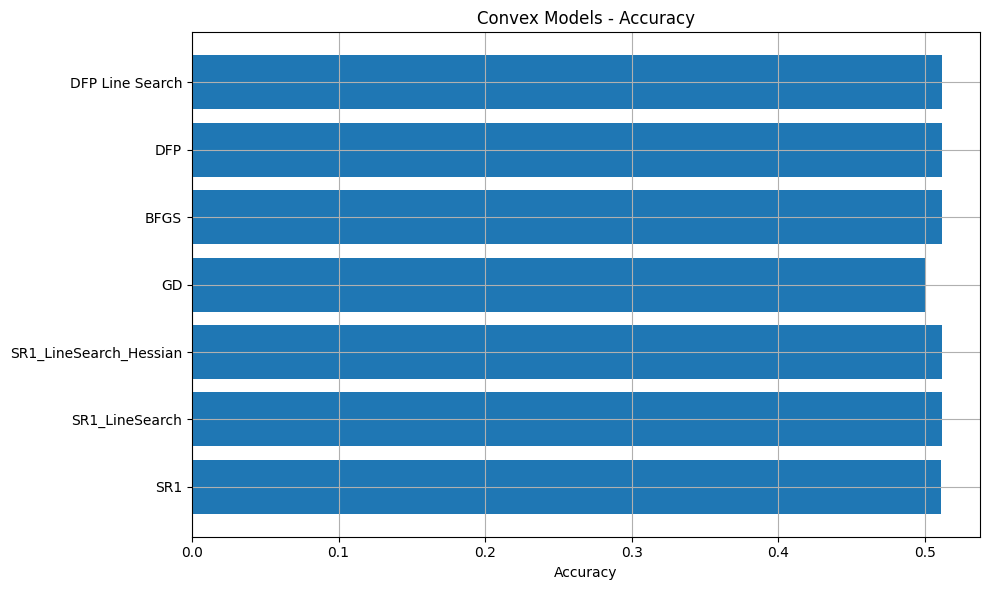

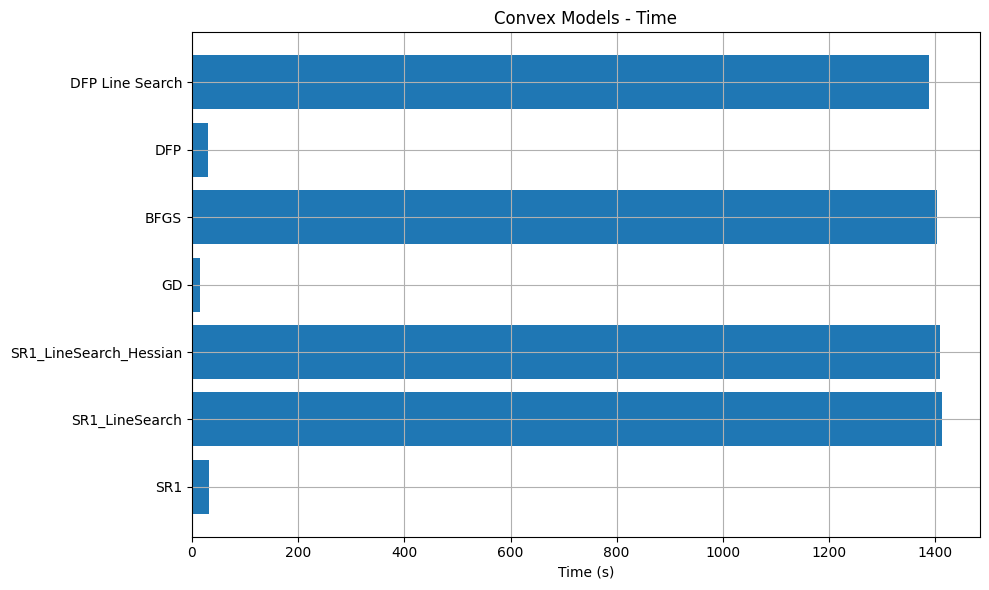

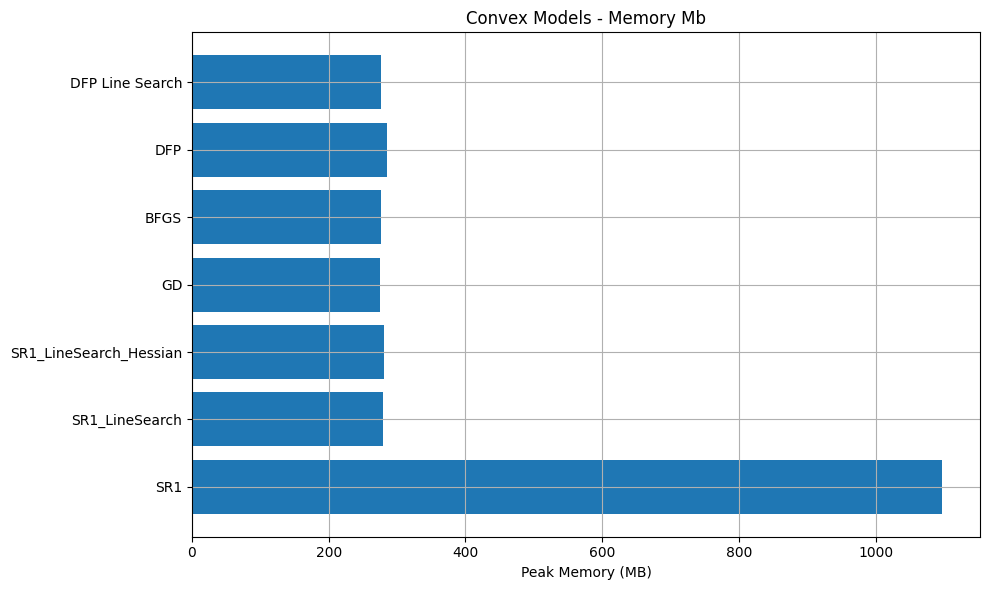

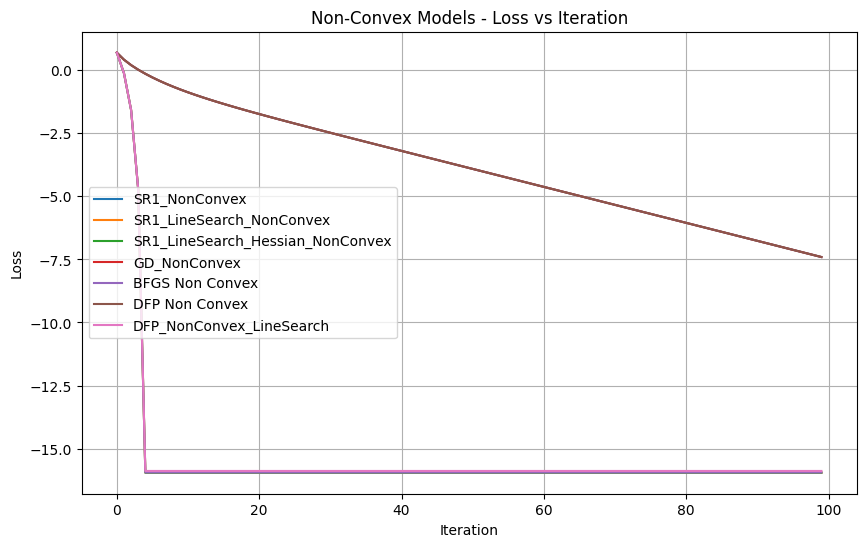

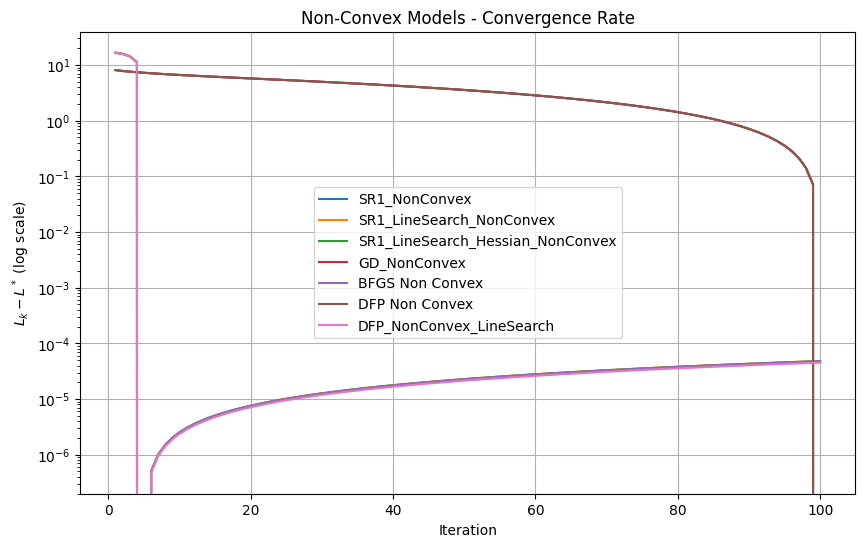

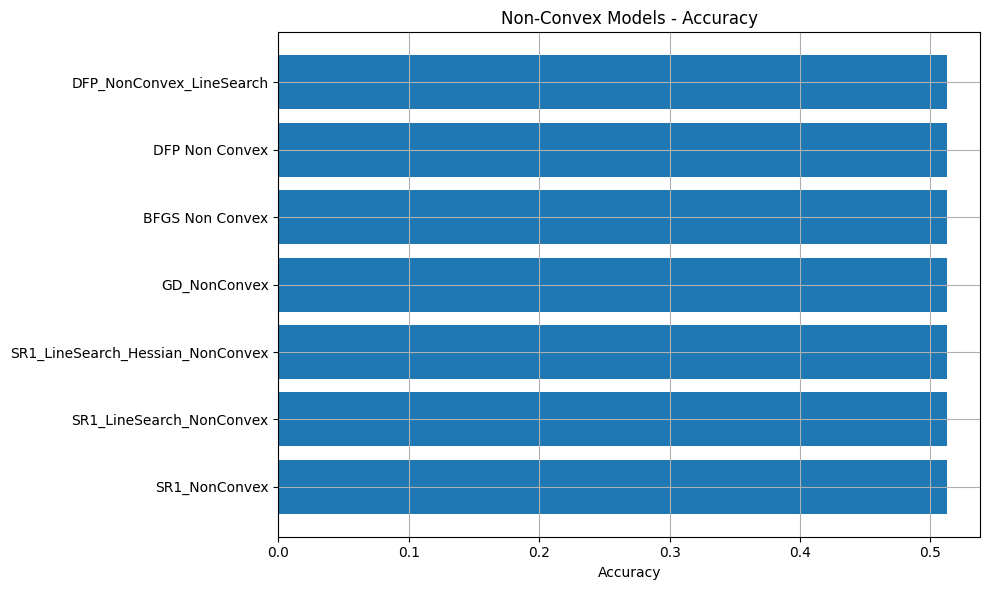

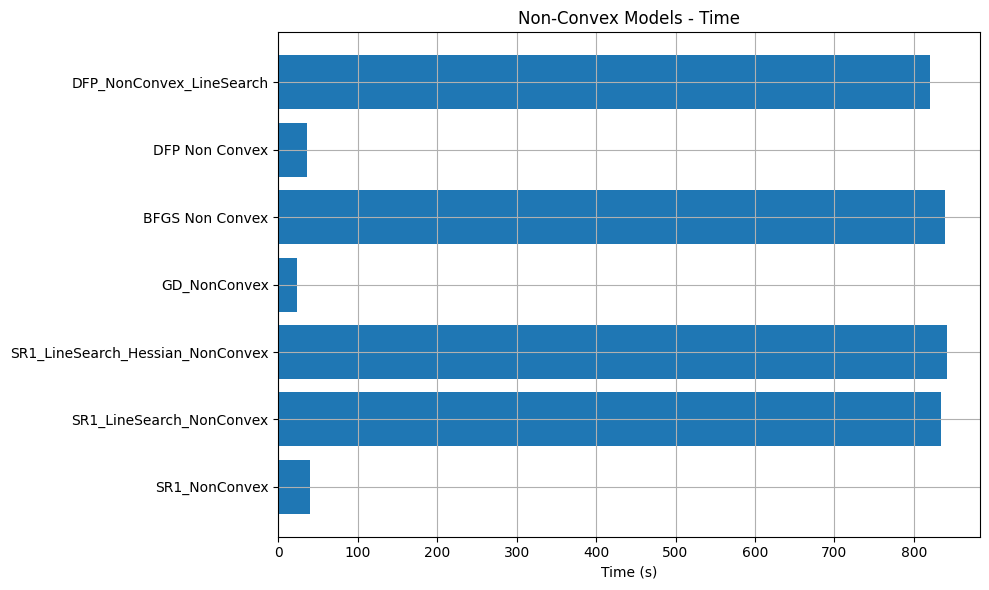

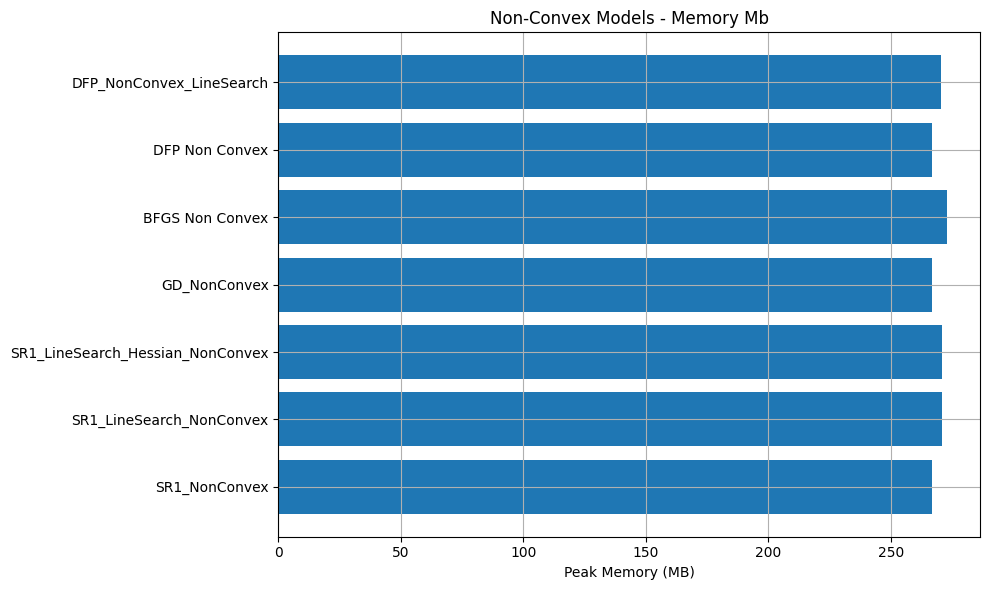


Convex Models - Convergence Summary (ε=1e-06, patience=5)
| Model                  |   Convergence Iteration |   Accuracy |
|------------------------|-------------------------|------------|
| SR1                    |                       9 |     0.5107 |
| SR1_LineSearch         |                     100 |     0.5117 |
| SR1_LineSearch_Hessian |                     100 |     0.5117 |
| GD                     |                     100 |     0.4997 |
| BFGS                   |                     100 |     0.5117 |
| DFP                    |                       9 |     0.5112 |
| DFP Line Search        |                     100 |     0.5118 |

Non-Convex Models - Convergence Summary (ε=1e-06, patience=5)
| Model                            |   Convergence Iteration |   Accuracy |
|----------------------------------|-------------------------|------------|
| SR1_NonConvex                    |                     100 |     0.5124 |
| SR1_LineSearch_NonConvex         |                    

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time
import tracemalloc
from sklearn.datasets import load_svmlight_file
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
import bz2


# Load the data
file_path = '/content/drive/MyDrive/data/covtype.libsvm.binary.bz2'

with bz2.open(file_path, 'rb') as f:
    X_sparse, y = load_svmlight_file(f)

# Convert to dense NumPy array
X = X_sparse.toarray()
y = np.array(y)

# Standardize features (zero mean, unit variance)
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Print shapes
print(type(X), X.shape)
print(type(y), y.shape)


# Define your model classes
convex_model_classes = {
    "SR1": LogisticRegressionSR1,
    "SR1_LineSearch": LogisticRegressionSR1LineSearch,
    "SR1_LineSearch_Hessian": LogisticRegressionSR1LineSearchWithHessianReg,
    "GD": LogisticRegressionGD,
    "BFGS": LogisticRegressionBFGS,
    "DFP": LogisticRegressionDFP,
    "DFP Line Search": LogisticRegressionDFPLineSearch,



}

nonconvex_model_classes = {
    "SR1_NonConvex": LogisticRegressionSR1NonConvexReg,
    "SR1_LineSearch_NonConvex": LogisticRegressionSR1NonConvexRegLineSearch,
    "SR1_LineSearch_Hessian_NonConvex": LogisticRegressionSR1NonConvexRegLineSearchWithHessianReg,
    "GD_NonConvex": LogisticRegressionGDNonConvexReg,
    "BFGS Non Convex": LogisticRegressionBFGSNonConvex,
    "DFP Non Convex": LogisticRegressionNonConvexDFP,
    "DFP_NonConvex_LineSearch": LogisticRegressionDFPNonConvexLineSearch


}


def run_experiment(model_class, X, y, model_name):
    initial_params = np.zeros(X.shape[1] + 1)
    model = model_class(initial_params=initial_params)
    tracemalloc.start()
    start_time = time.time()
    model.fit(X, y)
    end_time = time.time()
    current, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    y_pred = model.predict(X)
    acc = accuracy_score(y, y_pred)

    return {
        "model": model_name,
        "step_size": None,
        "time": end_time - start_time,
        "memory_MB": peak / (1024 ** 2),
        "losses": model.losses,
        "accuracy": acc
    }

# Run convex experiments
convex_results = []
for name, cls in convex_model_classes.items():
    print(f"Running {name}")
    try:
        result = run_experiment(cls, X, y, model_name=name)
        convex_results.append(result)
    except Exception as e:
        print(f"Failed for {name}: {e}")

# Run non-convex experiments
nonconvex_results = []
for name, cls in nonconvex_model_classes.items():
    print(f"Running {name}")
    try:
        result = run_experiment(cls, X, y, model_name=name)
        nonconvex_results.append(result)
    except Exception as e:
        print(f"Failed for {name}: {e}")

# Plotting function (unchanged)
def plot_results(results, title_prefix):
    # Loss vs Iteration
    plt.figure(figsize=(10,6))
    for res in results:
        label = f"{res['model']}"
        plt.plot(res['losses'], label=label)
    plt.xlabel("Iteration")
    plt.ylabel("Loss")
    plt.title(f"{title_prefix} - Loss vs Iteration")
    plt.legend()
    plt.grid(True)
    plt.show()

    # Convergence plot (log scale)
    plt.figure(figsize=(10,6))
    for res in results:
        losses = np.array(res["losses"])
        L_star = np.min(losses)
        errors = losses - L_star
        label = f"{res['model']}"
        plt.plot(range(1, len(errors)+1), errors, label=label)
    plt.yscale('log')
    plt.xlabel("Iteration")
    plt.ylabel(r"$L_k - L^*$ (log scale)")
    plt.title(f"{title_prefix} - Convergence Rate")
    plt.legend()
    plt.grid(True)
    plt.show()

    # Accuracy bar plot
    plt.figure(figsize=(10,6))
    names = []
    accs = []
    for res in results:
        label = f"{res['model']}"
        names.append(label)
        accs.append(res['accuracy'])
    plt.barh(names, accs)
    plt.xlabel("Accuracy")
    plt.title(f"{title_prefix} - Accuracy")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Time and memory
    for metric in ["time", "memory_MB"]:
        plt.figure(figsize=(10,6))
        vals = [res[metric] for res in results]
        plt.barh(names, vals)
        plt.xlabel("Time (s)" if metric == "time" else "Peak Memory (MB)")
        plt.title(f"{title_prefix} - {metric.replace('_', ' ').title()}")
        plt.grid(True)
        plt.tight_layout()
        plt.show()

# Plot convex and non-convex results separately
plot_results(convex_results, "Convex Models")
plot_results(nonconvex_results, "Non-Convex Models")

def detect_convergence(losses, epsilon=1e-6, patience=5):
    """
    Returns the iteration at which convergence is detected.
    Convergence is defined as `patience` consecutive changes below `epsilon`.
    Returns len(losses) if convergence was never reached.
    """
    counter = 0
    for i in range(1, len(losses)):
        delta = abs(losses[i] - losses[i-1])
        if delta < epsilon:
            counter += 1
            if counter >= patience:
                return i - patience + 1  # point where stability started
        else:
            counter = 0
    return len(losses)

def summarize_convergence(results, title, epsilon=1e-6, patience=5):
    print(f"\n{title} - Convergence Summary (ε={epsilon}, patience={patience})")
    table = []
    for res in results:
        model_name = res["model"]
        losses = res["losses"]
        conv_iter = detect_convergence(losses, epsilon=epsilon, patience=patience)
        accuracy = res["accuracy"]
        table.append([model_name, conv_iter, f"{accuracy:.4f}"])
    print(tabulate(table, headers=["Model", "Convergence Iteration", "Accuracy"], tablefmt="github"))

summarize_convergence(convex_results, "Convex Models")
summarize_convergence(nonconvex_results, "Non-Convex Models")
